# Growth Recursive — Kernel

## Setup

[JAX](https://docs.jax.dev) underlies everything below: array math via
`jax.numpy`,
[compilation](https://docs.jax.dev/en/latest/jit-compilation.html) via
`jax.jit`, and exact derivatives via [automatic
differentiation](https://docs.jax.dev/en/latest/automatic-differentiation.html)
— the solver differentiates the residual program itself, so no
derivative is coded by hand. JAX defaults to 32-bit floats, so we switch
on 64-bit and the most accurate matmul *before* creating any array, then
import everything we need.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)
jax.config.update("jax_default_matmul_precision", "highest")

import math
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
from nlls_gram import RepeatedFactorMetric, RidgeLevenbergMarquardt
from tinydiffeq import RK4, ConstantStepSize, SaveAt, solve_bvp, solve_ode

Structural parameters: the sequential calibration plus balanced growth
at rate $g$. Technology is Hicks-neutral, $f(z, k) = z k^a$ with
$z(t) = z_0 e^{(1-a) g t}$, so the labor-augmenting index $z^{1/(1-a)}$
grows at $g$ and detrended quantities are stationary. The dict `p` is
the solver’s differentiable-parameter pytree —
[`nlls-gram`](https://pypi.org/project/nlls-gram/) differentiates the
solve implicitly with respect to every leaf. The initial state
$(z_0, k_0)$ is not a leaf: nothing is integrated during training, so it
enters only the collocation design and the held-out rollouts.

In [2]:
a = 1.0 / 3.0  # capital share in f(z, k) = z k^a
delta = 0.1  # depreciation rate
rho_hat = -4.0 * math.log(0.9896)  # continuous discount rate (quarterly beta anchor)
sigma_crra = 2.0  # CRRA curvature
g = 0.02  # balanced growth rate; TFP z grows at (1 - a) g
z_0 = 1.0  # initial TFP
k_0 = 1.0  # initial capital
p = {"a": a, "delta": delta, "rho_hat": rho_hat, "sigma_crra": sigma_crra, "g": g}

Parameters of the algorithm: the state-kernel hyperparameters, the
collocation design and simulation horizons, the ridge
Levenberg–Marquardt settings, and the benchmark boundary-value solve.

In [3]:
AMPLITUDE = 1.0  # RBF amplitude
LENGTHSCALE = 0.6  # RBF length scale in log kappa
METRIC_EPSILON = 3e-5  # diagonal shift before the Cholesky metric factor
TRAIN_T = 100.0
TRAIN_POINTS = 65  # collocation states (and RBF centers) on the benchmark path
TEST_T = 40.0
TEST_STEPS = 40
TVC_T = 200.0
TVC_STEPS = 256
RIDGE = 1e-12  # disappearing penalty weight
ATOL = 1e-5
GTOL = 1e-7
INIT_DAMPING = 1e-6
DAMPING_DECREASE = 0.25
MAX_STEPS = 100
BVP_T = 200.0
BVP_POINTS = 201
BVP_TOL = 1e-10
BVP_MAX_NODES = 2048

## The model

The recursive formulation works on the log state $x = (\log z, \log k)$
and seeks an investment *policy* $i(x)$ rather than a time path. Given a
policy, the state drifts as

$$
\frac{d \log z}{dt} = (1 - a)\, g,
\qquad
\frac{d \log k}{dt} = \frac{i(x)}{k} - \delta,
$$

with consumption from the resource constraint, $c(x) = z k^a - i(x)$,
and optimality is the Euler equation along the flow,

$$
\frac{d \log c}{dt} = \frac{1}{\sigma}\big(a\, z\, k^{a-1} - \delta - \hat\rho\big).
$$

## Collocation states from a benchmark solve

A state-space method needs states to collocate on. Here they come from a
saddle-path solve in the detrended coordinates
$\kappa = k\, z^{-1/(1-a)}$, $\tilde c = c\, z^{-1/(1-a)}$,

$$
\kappa' = \kappa^a - \tilde c - (\delta + g)\, \kappa,
\qquad
\tilde c' = \frac{\tilde c}{\sigma}\big(a \kappa^{a-1} - \hat\rho - \delta - \sigma g\big),
$$

with $\kappa(0) = \kappa_0$ and the terminal pin
$\kappa(T) = \kappa_{ss}$, solved by
[`tinydiffeq`](https://github.com/HighDimensionalEconLab/tinydiffeq)’s
`solve_bvp` (a JAX port of scipy’s collocation method). The initial
guess approaches the steady state at the linearized stable eigenvalue —
a naive flat guess sends Newton to a spurious branch on long horizons.

In [4]:
kappa_0 = k_0 / z_0 ** (1.0 / (1.0 - a))
kappa_ss = ((delta + rho_hat + sigma_crra * g) / a) ** (1.0 / (a - 1.0))


def kappa_field(_, y):
    kappa, c_tilde = y
    return jnp.array(
        [
            kappa**a - c_tilde - (delta + g) * kappa,
            (c_tilde / sigma_crra)
            * (a * kappa ** (a - 1.0) - rho_hat - delta - sigma_crra * g),
        ]
    )


def kappa_bc(ya, yb):
    return jnp.array([ya[0] - kappa_0, yb[0] - kappa_ss])


mesh = jnp.linspace(0.0, BVP_T, BVP_POINTS)
c_tilde_ss = kappa_ss**a - (delta + g) * kappa_ss
f_pp = a * (a - 1.0) * kappa_ss ** (a - 2.0)
trace = rho_hat + (sigma_crra - 1.0) * g
lambda_stable = 0.5 * (
    trace - jnp.sqrt(trace**2 - 4.0 * c_tilde_ss * f_pp / sigma_crra)
)
kappa_guess = kappa_ss + (kappa_0 - kappa_ss) * jnp.exp(lambda_stable * mesh)
y_guess = jnp.stack([kappa_guess, kappa_guess**a - (delta + g) * kappa_guess], axis=-1)
benchmark = solve_bvp(
    kappa_field, kappa_bc, mesh, y_guess, tol=BVP_TOL, max_nodes=BVP_MAX_NODES
)

The benchmark places the training states: its path, sampled on the
training dates and re-trended to $(\log z, \log k)$, is the collocation
design, and the sampled $\log \kappa$ values double as the kernel
centers. Nothing is integrated during training — this is a
representation size, not a simulation grid. Unlike the recursive NN
notebook, which trains on the closed-loop rollout its own policy
generates, this collocation design is fixed data. The same benchmark
returns at the end as the accuracy reference on the held-out rollout.

In [5]:
t_train = jnp.linspace(0.0, TRAIN_T, TRAIN_POINTS)
log_z_train = jnp.log(z_0) + (1.0 - a) * g * t_train
log_k_train = jnp.log(benchmark(t_train)[:, 0]) + log_z_train / (1.0 - a)
train_log_states = jnp.stack([log_z_train, log_k_train], axis=-1)
centers = log_k_train - log_z_train / (1.0 - a)

## The hypothesis class

The policy is *homothetic*: a Gaussian RBF expansion in the single
detrended state $\log \kappa = \log k - \log z / (1 - a)$,

$$
i(x) = \delta\, k\; U\!\Big( \textstyle\sum_j \alpha_j\, \sigma^2 e^{-(\log\kappa - q_j)^2 / 2\ell^2} + b \Big),
$$

with centers $q_j$ at the collocation states, an unpenalized free
constant $b$, and the normalized softplus $U$ (with $U(0) = U'(0) = 1$)
anchoring a near-zero expansion at exact replacement investment
$i = \delta k$.

In [6]:
def rbf_features(q):
    return AMPLITUDE**2 * jnp.exp(
        -((q[..., None] - centers) ** 2) / (2.0 * LENGTHSCALE**2)
    )


def unit_softplus(raw):
    return jax.nn.softplus(2.0 * jnp.log(2.0) * raw) / jnp.log(2.0)


def investment(theta, log_state, p):
    alpha, b = theta["alpha"], theta["b"]
    log_kappa = log_state[1] - log_state[0] / (1.0 - p["a"])
    return (
        p["delta"]
        * jnp.exp(log_state[1])
        * unit_softplus(rbf_features(log_kappa) @ alpha + b)
    )

## Model functions

Consumption clears the resource constraint, the drift is the model’s law
of motion under the policy, and the Euler residual takes $d \log c / dt$
as a forward-mode
[`jax.jvp`](https://docs.jax.dev/en/latest/automatic-differentiation.html)
of $\log c(x)$ along that drift. Held-out trajectories come from
[`tinydiffeq`](https://github.com/HighDimensionalEconLab/tinydiffeq)’s
fixed-step RK4 `solve_ode`, saving the integrator’s own states.

In [7]:
def consumption(theta, log_state, p):
    z, k = jnp.exp(log_state)
    return z * k ** p["a"] - investment(theta, log_state, p)


def log_state_drift(theta, log_state, p):
    log_k = log_state[1]
    return jnp.stack(
        [
            (1.0 - p["a"]) * p["g"],
            investment(theta, log_state, p) / jnp.exp(log_k) - p["delta"],
        ]
    )


def euler_residual(theta, log_state, p):
    drift = log_state_drift(theta, log_state, p)
    log_c, dlog_c_dt = jax.jvp(
        lambda state: jnp.log(consumption(theta, state, p)), (log_state,), (drift,)
    )
    z, k = jnp.exp(log_state)
    # 0 * log_c is NaN where c <= 0; the tangent alone would stay finite there.
    return (
        dlog_c_dt
        + 0.0 * log_c
        - (p["a"] * z * k ** (p["a"] - 1.0) - p["delta"] - p["rho_hat"])
        / p["sigma_crra"]
    )


def simulate(theta, initial_log_state, T, n_steps, p):
    return solve_ode(
        lambda log_state: log_state_drift(theta, log_state, p),
        RK4(),
        0.0,
        T,
        initial_log_state,
        dt_0=T / n_steps,
        controller=ConstantStepSize(),
        max_steps=n_steps,
        save_at=SaveAt(steps=True),
    )

## Ridgeless least squares

The residual is Euler-only — the resource constraint is built into
$c(x) = z k^a - i(x)$ — enforced at the fixed collocation states:

$$
\min_{\alpha, b}\ \| r(\alpha, b) \|^2 + \lambda\, \alpha^\top (K + \varepsilon I)\, \alpha,
\qquad
r_j = \frac{1}{\sqrt n}\Big(
\frac{d \log c}{dt}\Big|_{x_j} - \frac{1}{\sigma}\big(a z_j k_j^{a-1} - \delta - \hat\rho\big)
\Big).
$$

As $\lambda \to 0$ this selects the interpolant of minimal RKHS norm
with the free constant $b$ unpenalized; $\varepsilon$ shifts the Gram’s
near-zero eigenvalues so its Cholesky factor exists.

In [8]:
def residual_fn(theta, args, p):
    euler = jax.vmap(lambda s: euler_residual(theta, s, p))(args)
    return euler / jnp.sqrt(euler.size)

## Solve

The penalty enters through a `RepeatedFactorMetric` holding the upper
Cholesky factor of the shifted Gram: it penalizes the leading block of
the flattened `theta` — dicts flatten by sorted key, so `"alpha"` leads
— and leaves the trailing scalar $b$ as the unpenalized free block.
`RidgeLevenbergMarquardt` adds a geodesic (second-order) correction to
each Gauss–Newton step by default, taking it when it is small relative
to the step itself. Convergence requires both the gradient (`gtol`) and
residual (`atol`) tests.

In [9]:
gram = rbf_features(centers)
metric = RepeatedFactorMetric(
    jnp.linalg.cholesky(gram + METRIC_EPSILON * jnp.eye(TRAIN_POINTS), upper=True),
    repeats=1,
)
# Flattened by sorted key: "alpha" (penalized by the metric) precedes the free "b".
theta_0 = {"alpha": jnp.zeros(TRAIN_POINTS), "b": jnp.zeros(())}

solver = RidgeLevenbergMarquardt(
    residual_fn,
    metric=metric,
    ridge=RIDGE,
    init_damping=INIT_DAMPING,
    damping_decrease=DAMPING_DECREASE,
)
start = time.perf_counter()
result = solver.solve(
    theta_0,
    train_log_states,
    p=p,
    max_steps=MAX_STEPS,
    atol=ATOL,
    gtol=GTOL,
    max_steps_is_success=False,
)
solve_time = time.perf_counter() - start
theta = result.x

## Results

The test rolls the learned policy closed-loop from $(z_0, k_0)$ over a
fresh horizon and evaluates the Euler residual along the roll, then
compares capital and consumption against the benchmark saddle path
re-trended to levels, $k^\star(t) = z_0^{1/(1-a)} e^{g t} \kappa(t)$.
The transversality certificate simulates to $T = 200$ and evaluates the
log of $e^{-\hat\rho T} c(T)^{-\sigma} k(T)$, normalized by its
initial-date value: far negative on the saddle path, positive on a
capital bubble.

In [10]:
initial_log_state = jnp.log(jnp.array([z_0, k_0]))
test_solution = simulate(theta, initial_log_state, TEST_T, TEST_STEPS, p)
euler_test = jax.vmap(lambda s: euler_residual(theta, s, p))(test_solution.xs)
z_test, k_test = jnp.exp(test_solution.xs).T
c_test = jax.vmap(lambda s: consumption(theta, s, p))(test_solution.xs)

scale_test = z_0 ** (1.0 / (1.0 - a)) * jnp.exp(g * test_solution.ts)
kappa_benchmark, c_tilde_benchmark = benchmark(test_solution.ts).T
k_error = jnp.abs(k_test - scale_test * kappa_benchmark) / (
    scale_test * kappa_benchmark
)
c_error = jnp.abs(c_test - scale_test * c_tilde_benchmark) / (
    scale_test * c_tilde_benchmark
)

# Log transversality certificate at T, normalized by its initial-date value:
# (-rho_hat T - sigma log c(T) + log k(T)) - (-sigma log c(0) + log k(0)).
tvc_solution = simulate(theta, initial_log_state, TVC_T, TVC_STEPS, p)
terminal_log_state = tvc_solution.xs[-1]
c_T = consumption(theta, terminal_log_state, p)
k_T = jnp.exp(terminal_log_state[1])
c_init = consumption(theta, initial_log_state, p)
log_tvc = (-rho_hat * TVC_T - sigma_crra * jnp.log(c_T) + jnp.log(k_T)) - (
    -sigma_crra * jnp.log(c_init) + jnp.log(k_0)
)

print(f"solve: {int(result.steps)} steps in {solve_time:.2f}s (incl. jit)")
print(f"train loss: {float(result.info.resid_loss):.3e}")
print(f"mean |Euler residual| test roll: {float(jnp.abs(euler_test).mean()):.3e}")
print(
    f"mean relative error vs benchmark: k {float(k_error.mean()):.3e}, "
    f"c {float(c_error.mean()):.3e}"
)
print(f"log-TVC at t={TVC_T:.0f}: {float(log_tvc):.1f}   (should be << 0)")

solve: 15 steps in 0.92s (incl. jit)
train loss: 3.038e-11
mean |Euler residual| test roll: 9.702e-06
mean relative error vs benchmark: k 1.729e-05, c 1.406e-05
log-TVC at t=200: -12.3   (should be << 0)

Detrended capital $\kappa = k\, z^{-1/(1-a)}$ tracks the benchmark
(dashed) up toward the balanced-growth steady state $\kappa_{ss}$ along
the test roll, and the Euler residual sits on zero.

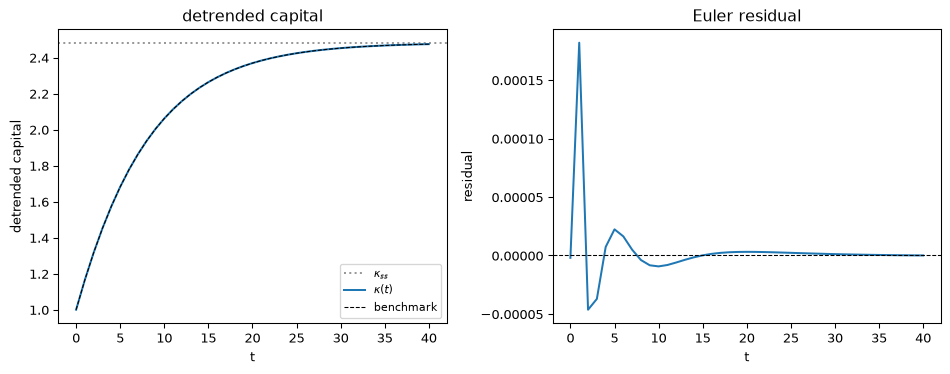

In [11]:
kappa_test = k_test / z_test ** (1.0 / (1.0 - a))

fig, (ax_k, ax_r) = plt.subplots(1, 2, figsize=(10, 4))
ax_k.axhline(float(kappa_ss), color="0.6", linestyle=":", label=r"$\kappa_{ss}$")
ax_k.plot(test_solution.ts, kappa_test, "C0", label=r"$\kappa(t)$")
ax_k.plot(test_solution.ts, kappa_benchmark, "k--", linewidth=0.8, label="benchmark")
ax_k.set(xlabel="t", ylabel="detrended capital", title="detrended capital")
ax_k.legend(fontsize=8)
ax_r.plot(test_solution.ts, euler_test, "C0")
ax_r.axhline(0.0, color="k", linestyle="--", linewidth=0.8)
ax_r.set(xlabel="t", ylabel="residual", title="Euler residual")
fig.tight_layout()
plt.show()